In [4]:
import pandas as pd

# The CSV has NO header, so we supply the column names ourselves
columns = [
    'Age', 'Gender', 'Total_Bilirubin', 'Direct_Bilirubin',
    'Alkaline_Phosphotase', 'Alamine_Aminotransferase',
    'Aspartate_Aminotransferase', 'Total_Proteins', 'Albumin',
    'Albumin_and_Globulin_Ratio', 'Class'
]

df = pd.read_csv(
    r'C:\Users\startklar\PycharmProjects\ds-sose2026-mt\Data Science project\ilpd+indian+liver+patient+dataset\ilpd.csv',
    header=None,
    names=columns
)

print(df.shape)      # should print (583, 11)
print(df.head())     # first 5 rows
print(df.info())     # column types + missing values

(583, 11)
   Age  Gender  Total_Bilirubin  Direct_Bilirubin  Alkaline_Phosphotase  \
0   65  Female              0.7               0.1                   187   
1   62    Male             10.9               5.5                   699   
2   62    Male              7.3               4.1                   490   
3   58    Male              1.0               0.4                   182   
4   72    Male              3.9               2.0                   195   

   Alamine_Aminotransferase  Aspartate_Aminotransferase  Total_Proteins  \
0                        16                          18             6.8   
1                        64                         100             7.5   
2                        60                          68             7.0   
3                        14                          20             6.8   
4                        27                          59             7.3   

   Albumin  Albumin_and_Globulin_Ratio  Class  
0      3.3                        0.90  

In [5]:
# 1. How big is the dataset?
print(df.shape)

# 2. What is each column, and are there missing values?
print(df.info())

# 3. Descriptive statistics for every numeric column
print(df.describe())

# 4. Count the missing values in each column
print(df.isnull().sum())

# 5. How many patients are in each class? (our target)
print(df['Class'].value_counts())

(583, 11)
<class 'pandas.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    str    
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Proteins              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Class                       583 non-null    int64  
dtypes: float64(5), int64(5), str(1)
memory usage: 50.2 KB
None
              Age  Total_Bilirubin  Direct_Bilirubin  Alkaline_Phosphotase  \
count  583.00

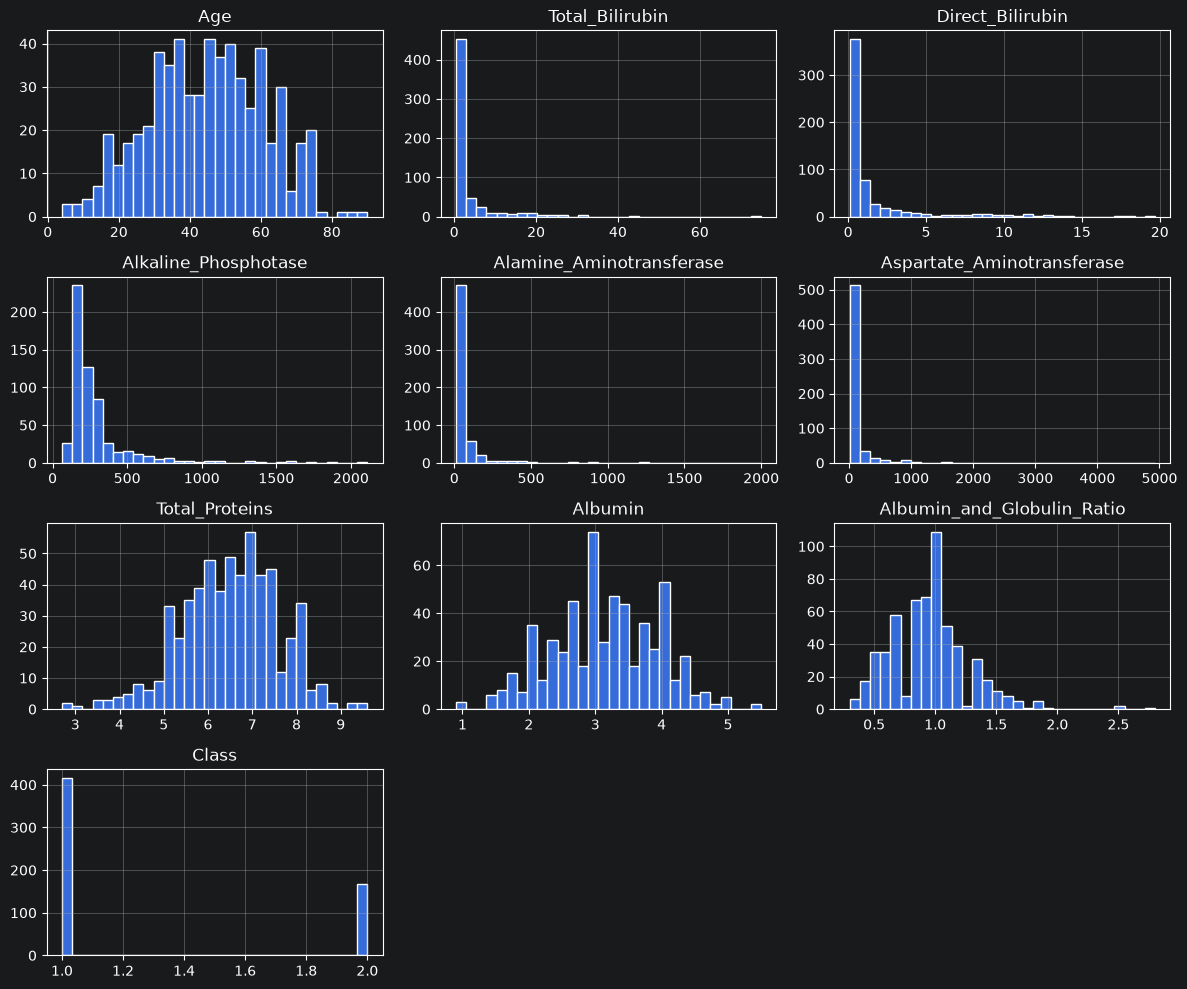

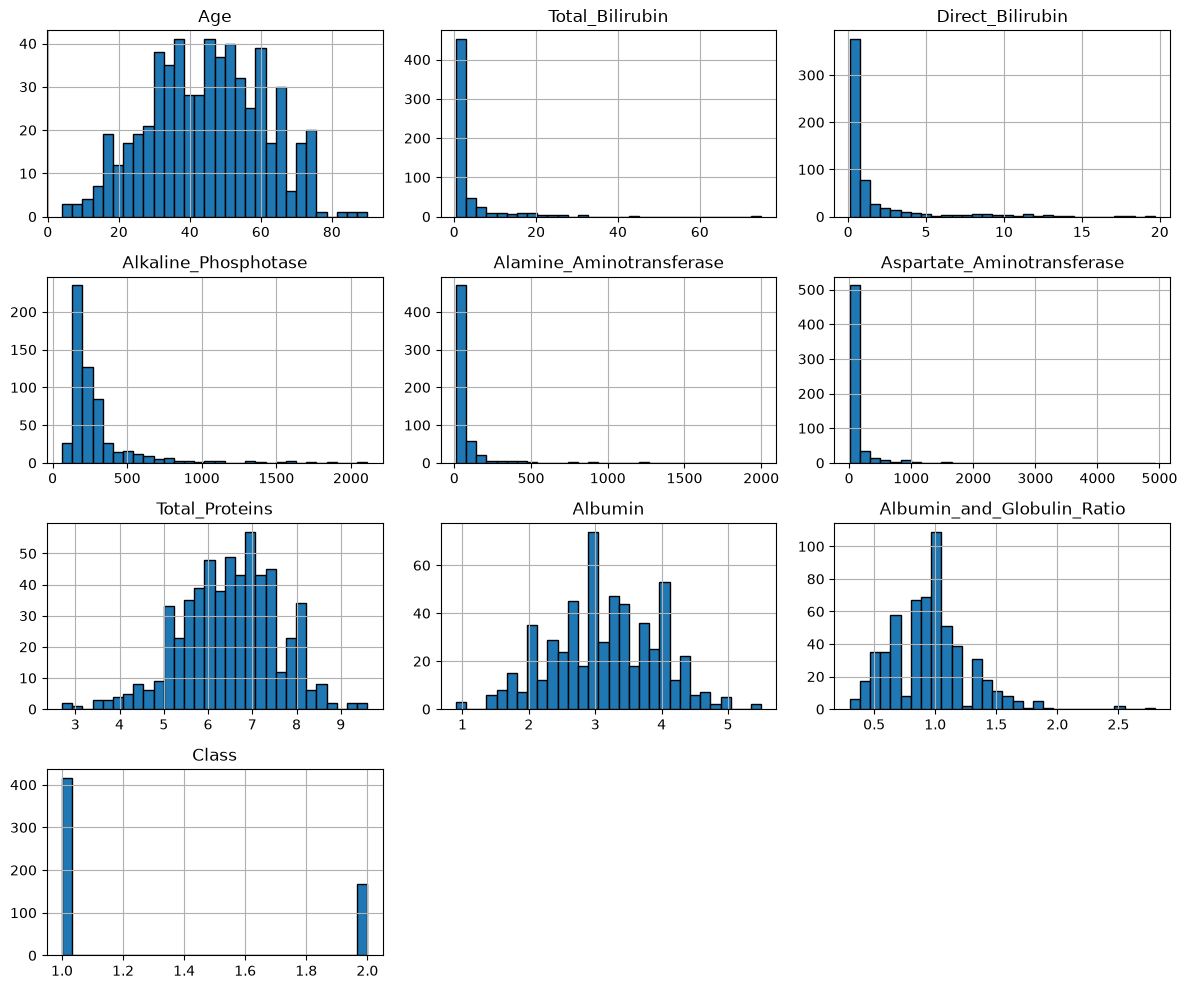

In [37]:
import matplotlib.pyplot as plt

df.hist(figsize=(12, 10), bins=30, edgecolor='white')
plt.style.use('default')
plt.tight_layout()
plt.show()

df.hist(figsize=(12, 10), bins=30, edgecolor='black')
plt.tight_layout()
plt.savefig('fig1_histograms.png', dpi=300, bbox_inches='tight')
plt.show()

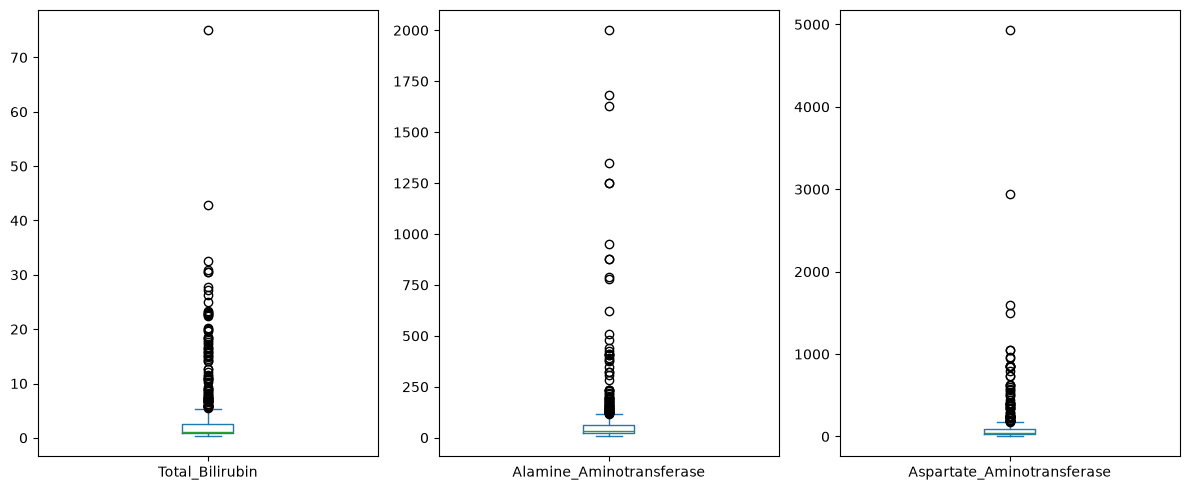

In [43]:
import matplotlib.pyplot as plt

# Pick a few skewed columns to inspect for outliers
cols_to_check = ['Total_Bilirubin', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase']

df[cols_to_check].plot(kind='box', subplots=True, figsize=(12, 5))
plt.tight_layout()
plt.savefig('fig2_boxplots.png', dpi=300, bbox_inches='tight')
plt.show()


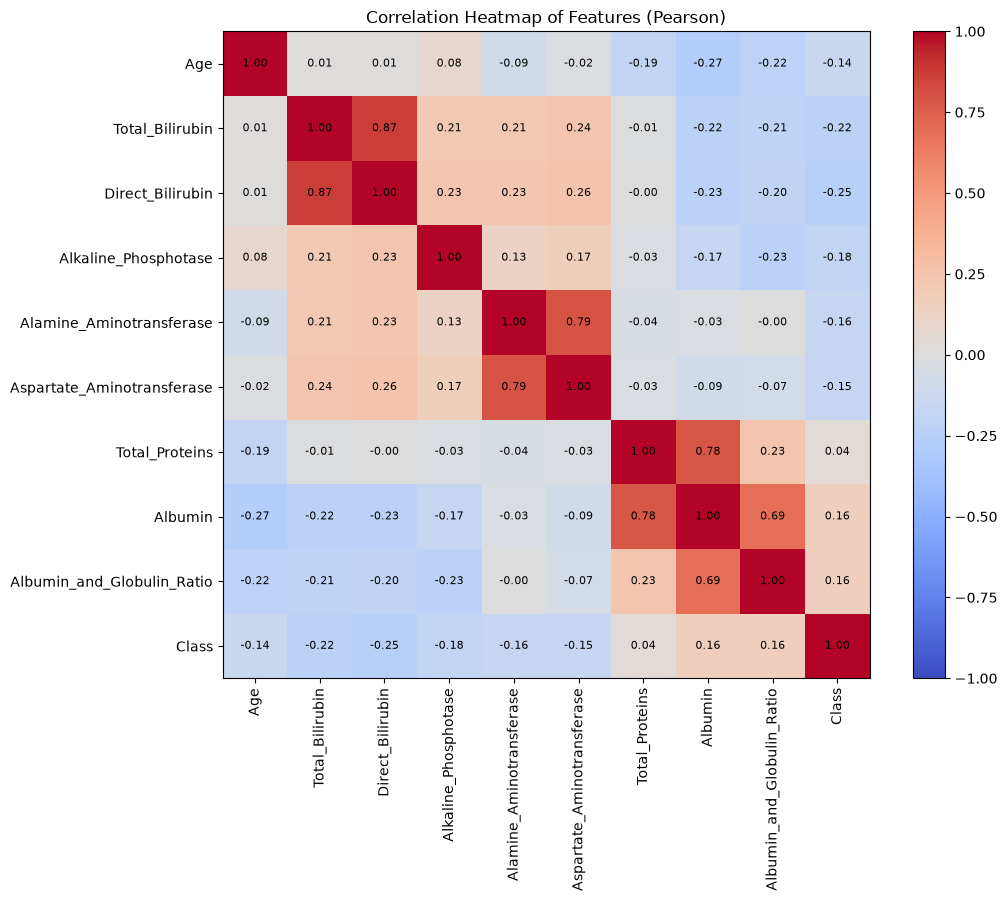

In [47]:
import matplotlib.pyplot as plt

# 1. Compute the correlation matrix (Pearson, numeric columns only)
corr = df.corr(numeric_only=True)

# 2. Set up the figure and draw the grid of colors
fig, ax = plt.subplots(figsize=(11, 9))
cax = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

# 3. Add the colorbar (the legend showing which color = which value)
fig.colorbar(cax)

# 4. Put the column names on both axes
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticklabels(corr.columns)

# 5. Write the actual number inside each cell
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}',
                ha='center', va='center', color='black', fontsize=8)

ax.set_title('Correlation Heatmap of Features (Pearson)')
plt.tight_layout()
plt.savefig('fig3_pearson.png', dpi=300, bbox_inches='tight')
plt.show()

In [15]:
df_clean = df.dropna()
print(df_clean.shape)
print(df_clean.isnull().sum().sum())

(579, 11)
0


In [16]:
df_clean = df_clean.copy()
df_clean['Gender'] = df_clean['Gender'].map({'Female': 0, 'Male': 1})
print(df_clean['Gender'].value_counts())
print(df_clean.dtypes)

Gender
1    439
0    140
Name: count, dtype: int64
Age                             int64
Gender                          int64
Total_Bilirubin               float64
Direct_Bilirubin              float64
Alkaline_Phosphotase            int64
Alamine_Aminotransferase        int64
Aspartate_Aminotransferase      int64
Total_Proteins                float64
Albumin                       float64
Albumin_and_Globulin_Ratio    float64
Class                           int64
dtype: object


In [19]:
from sklearn.model_selection import train_test_split

# 1. Separate features (X) from the target (y)
X = df_clean.drop('Class', axis=1)
y = df_clean['Class']

# 2. Split into training and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Check the sizes
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print(y_train.value_counts(normalize=True))

Training set: (463, 10)
Test set: (116, 10)
Class
1    0.714903
2    0.285097
Name: proportion, dtype: float64


In [24]:
from sklearn.preprocessing import StandardScaler

# 1. Create the scaler
scaler = StandardScaler()

# 2. Fit on training data ONLY, then transform it
X_train_scaled = scaler.fit_transform(X_train)

# 3. Apply the SAME scaling to the test data
X_test_scaled = scaler.transform(X_test)

# 4. Quick check: means should be ~0, stds ~1 on the training set
import numpy as np
print("Means after scaling:", np.round(X_train_scaled.mean(axis=0), 2))
print("Stds after scaling:", np.round(X_train_scaled.std(axis=0), 2))

Means after scaling: [-0.  0.  0.  0. -0. -0.  0. -0.  0. -0.]
Stds after scaling: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [25]:
from sklearn.linear_model import LogisticRegression

# 1. Create the model
log_reg = LogisticRegression(max_iter=1000, random_state=42)

# 2. Train it on the scaled training data
log_reg.fit(X_train_scaled, y_train)

# 3. Make predictions on the unseen test data
y_pred = log_reg.predict(X_test_scaled)

# 4. Quick first look at accuracy
from sklearn.metrics import accuracy_score
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7155172413793104


In [26]:
from sklearn.metrics import confusion_matrix, classification_report

# 1. The confusion matrix (the 2x2 table of TP, TN, FP, FN)
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# 2. Full report: precision, recall, f1-score for each class
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[74  9]
 [24  9]]

Classification Report:
              precision    recall  f1-score   support

           1       0.76      0.89      0.82        83
           2       0.50      0.27      0.35        33

    accuracy                           0.72       116
   macro avg       0.63      0.58      0.59       116
weighted avg       0.68      0.72      0.69       116



In [27]:
# 1. Same model, but now balanced
log_reg_balanced = LogisticRegression(
    max_iter=1000, random_state=42, class_weight='balanced'
)

# 2. Train on the scaled training data
log_reg_balanced.fit(X_train_scaled, y_train)

# 3. Predict on the unseen test data
y_pred_balanced = log_reg_balanced.predict(X_test_scaled)

# 4. Evaluate — compare against the first model
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Accuracy:", accuracy_score(y_test, y_pred_balanced))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))

Accuracy: 0.5689655172413793

Confusion Matrix:
[[39 44]
 [ 6 27]]

Classification Report:
              precision    recall  f1-score   support

           1       0.87      0.47      0.61        83
           2       0.38      0.82      0.52        33

    accuracy                           0.57       116
   macro avg       0.62      0.64      0.56       116
weighted avg       0.73      0.57      0.58       116



In [28]:
from sklearn.ensemble import RandomForestClassifier

# 1. Create the forest (500 trees, matching the lecture's rule of thumb)
rf = RandomForestClassifier(n_estimators=500, random_state=42)

# 2. Train it on the UNSCALED training data (trees don't need scaling)
rf.fit(X_train, y_train)

# 3. Predict on the unseen test data
y_pred_rf = rf.predict(X_test)

# 4. Evaluate
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.7155172413793104

Confusion Matrix:
[[71 12]
 [21 12]]

Classification Report:
              precision    recall  f1-score   support

           1       0.77      0.86      0.81        83
           2       0.50      0.36      0.42        33

    accuracy                           0.72       116
   macro avg       0.64      0.61      0.62       116
weighted avg       0.69      0.72      0.70       116



Alkaline_Phosphotase          0.151927
Aspartate_Aminotransferase    0.131098
Age                           0.122086
Alamine_Aminotransferase      0.121105
Total_Bilirubin               0.106610
Albumin                       0.094009
Direct_Bilirubin              0.088570
Total_Proteins                0.084984
Albumin_and_Globulin_Ratio    0.080325
Gender                        0.019286
dtype: float64


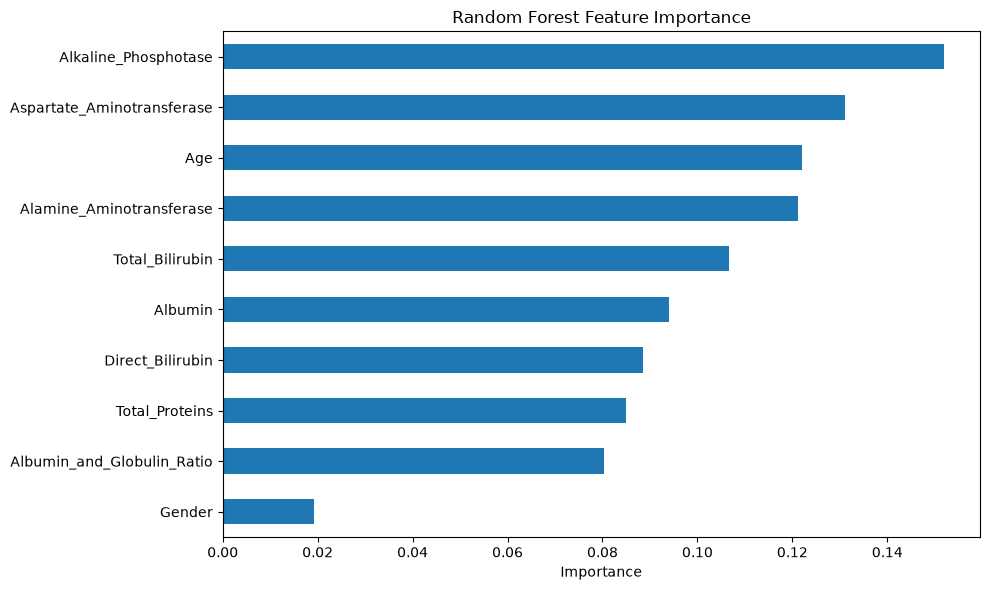

In [49]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Pull the importances out of the trained forest
importances = rf.feature_importances_

# 2. Attach feature names and sort from most to least important
feat_imp = pd.Series(importances, index=X_train.columns).sort_values(ascending=False)
print(feat_imp)

# 3. Plot as a horizontal bar chart
plt.figure(figsize=(10, 6))
feat_imp.sort_values().plot(kind='barh')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('fig7_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

In [30]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

# 1. Define the grid of settings to try
param_grid = {
    'n_estimators': [200, 500],
    'max_depth': [None, 10, 20],
    'min_samples_leaf': [1, 2, 5]
}

# 2. Set up the search: 5-fold cross-validation, optimizing macro F1
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

# 3. Run the search on TRAINING data only (test set stays sealed)
grid_search.fit(X_train, y_train)

# 4. See what won
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation F1 (macro):", grid_search.best_score_)

Best parameters: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 200}
Best cross-validation F1 (macro): 0.602624883914842


In [31]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from itertools import product

# Same grid of settings as the GridSearchCV version
n_estimators_list = [200, 500]
max_depth_list = [None, 10, 20]
min_samples_leaf_list = [1, 2, 5]

best_score = -1
best_params = None

# Loop manually over every combination (the lecture's style)
for n_est, depth, leaf in product(n_estimators_list, max_depth_list, min_samples_leaf_list):
    model = RandomForestClassifier(
        n_estimators=n_est,
        max_depth=depth,
        min_samples_leaf=leaf,
        random_state=42
    )
    # 5-fold cross-validation on the training data, scoring macro F1
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='f1_macro')
    mean_score = scores.mean()

    # Keep the best combination so far
    if mean_score > best_score:
        best_score = mean_score
        best_params = {'n_estimators': n_est, 'max_depth': depth, 'min_samples_leaf': leaf}

print("Best parameters (manual loop):", best_params)
print("Best cross-validation F1 (macro):", best_score)

Best parameters (manual loop): {'n_estimators': 200, 'max_depth': None, 'min_samples_leaf': 2}
Best cross-validation F1 (macro): 0.602624883914842


In [32]:
# Take the best model found by the search
best_rf = grid_search.best_estimator_

# Evaluate it ONCE on the sealed test set
y_pred_best = best_rf.predict(X_test)

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

Accuracy: 0.6896551724137931

Confusion Matrix:
[[70 13]
 [23 10]]

Classification Report:
              precision    recall  f1-score   support

           1       0.75      0.84      0.80        83
           2       0.43      0.30      0.36        33

    accuracy                           0.69       116
   macro avg       0.59      0.57      0.58       116
weighted avg       0.66      0.69      0.67       116



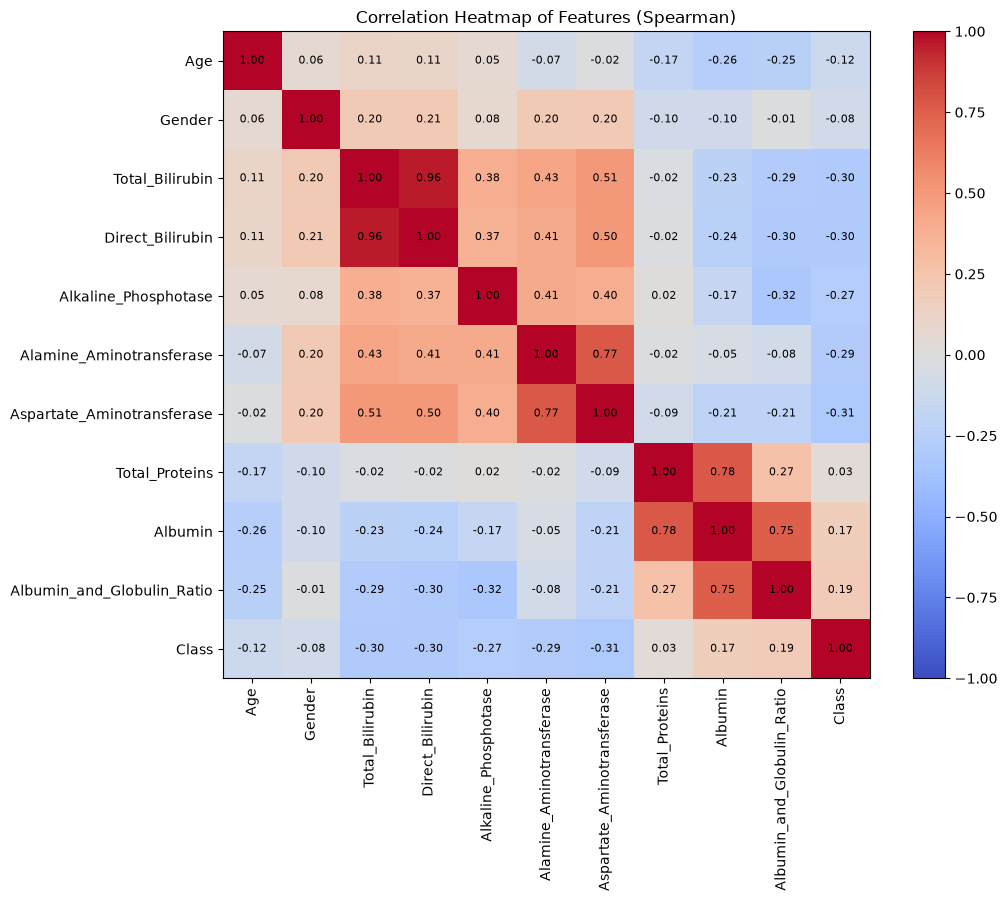

In [44]:
import matplotlib.pyplot as plt

# 1. Compute the correlation matrix using SPEARMAN (ranks) instead of Pearson
corr_spearman = df_clean.corr(method='spearman', numeric_only=True)

# 2. Draw the heatmap (same style as before)
fig, ax = plt.subplots(figsize=(11, 9))
cax = ax.imshow(corr_spearman, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax)

ax.set_xticks(range(len(corr_spearman.columns)))
ax.set_yticks(range(len(corr_spearman.columns)))
ax.set_xticklabels(corr_spearman.columns, rotation=90)
ax.set_yticklabels(corr_spearman.columns)

for i in range(len(corr_spearman.columns)):
    for j in range(len(corr_spearman.columns)):
        ax.text(j, i, f'{corr_spearman.iloc[i, j]:.2f}',
                ha='center', va='center', color='black', fontsize=8)

ax.set_title('Correlation Heatmap of Features (Spearman)')
plt.tight_layout()
plt.savefig('fig4_spearman.png', dpi=300, bbox_inches='tight')
plt.show()

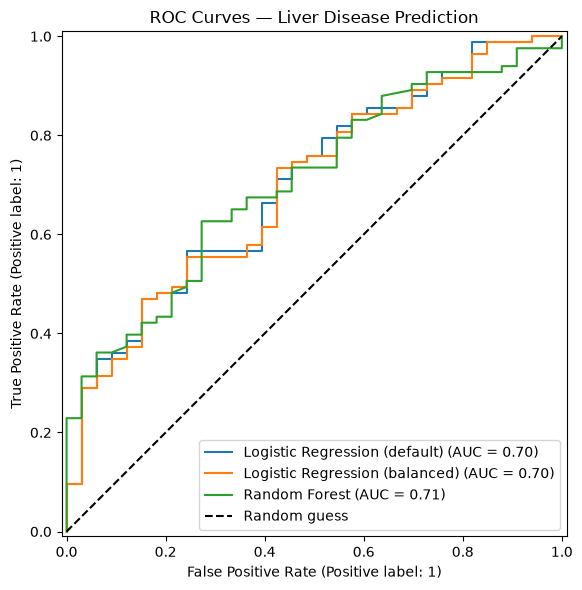

In [51]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 6))

# Plot ROC for each model (pos_label=1 means "diseased" is the positive class)
RocCurveDisplay.from_estimator(log_reg, X_test_scaled, y_test,
                               name='Logistic Regression (default)', pos_label=1, ax=ax)
RocCurveDisplay.from_estimator(log_reg_balanced, X_test_scaled, y_test,
                               name='Logistic Regression (balanced)', pos_label=1, ax=ax)
RocCurveDisplay.from_estimator(rf, X_test, y_test,
                               name='Random Forest', pos_label=1, ax=ax)

# The diagonal = a random-guessing baseline
ax.plot([0, 1], [0, 1], 'k--', label='Random guess')

ax.set_title('ROC Curves — Liver Disease Prediction')
ax.legend()
plt.tight_layout()
plt.savefig('fig_roc.png', dpi=300, bbox_inches='tight')
plt.show()

                        Accuracy  Recall (Diseased)  Recall (Healthy)  \
Model                                                                   
LogReg (default)           0.716              0.892             0.273   
LogReg (balanced)          0.569              0.470             0.818   
RandomForest (default)     0.716              0.855             0.364   
RandomForest (tuned)       0.690              0.843             0.303   

                        Macro F1  ROC-AUC  
Model                                      
LogReg (default)           0.585    0.704  
LogReg (balanced)          0.564    0.698  
RandomForest (default)     0.616    0.706  
RandomForest (tuned)       0.576    0.693  


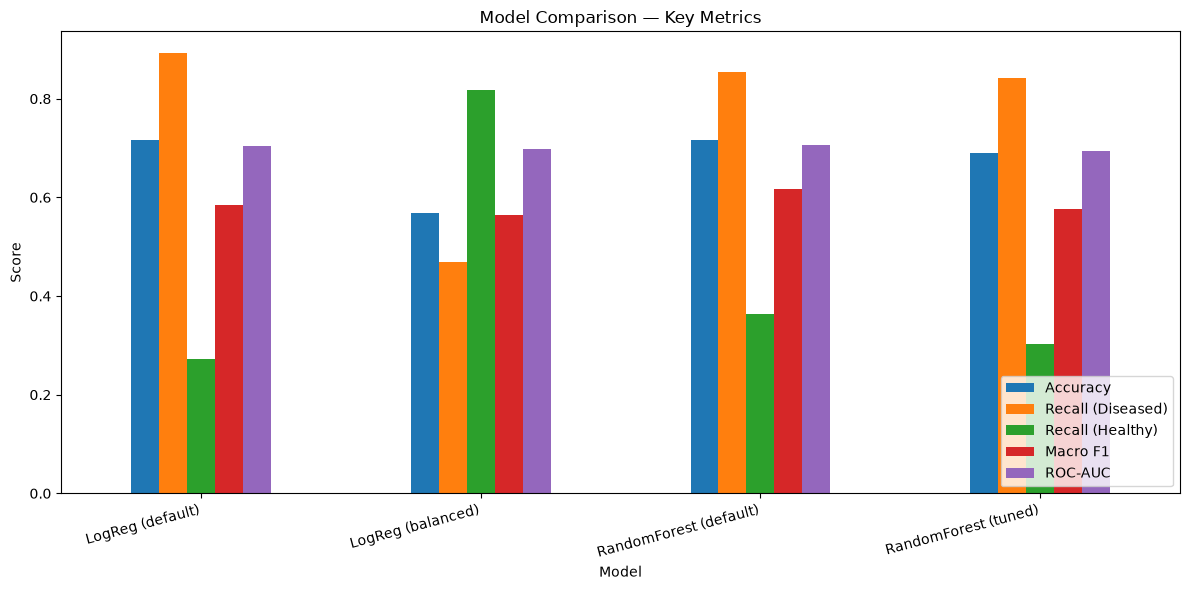

In [52]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score

# Binary version of the target: 1 = diseased (positive), 0 = healthy
y_test_bin = (y_test == 1).astype(int)

# Helper: gather key metrics for one model
def get_metrics(name, model, X_used, y_pred):
    proba_diseased = model.predict_proba(X_used)[:, 0]   # prob of class 1 (diseased)
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Recall (Diseased)': recall_score(y_test, y_pred, pos_label=1),
        'Recall (Healthy)': recall_score(y_test, y_pred, pos_label=2),
        'Macro F1': f1_score(y_test, y_pred, average='macro'),
        'ROC-AUC': roc_auc_score(y_test_bin, proba_diseased)
    }

# Collect all four models (note: logistic uses scaled X, forests use unscaled X)
results = [
    get_metrics('LogReg (default)',  log_reg,          X_test_scaled, y_pred),
    get_metrics('LogReg (balanced)', log_reg_balanced, X_test_scaled, y_pred_balanced),
    get_metrics('RandomForest (default)', rf,          X_test,        y_pred_rf),
    get_metrics('RandomForest (tuned)',   best_rf,     X_test,        y_pred_best),
]

# Build the summary table
summary = pd.DataFrame(results).set_index('Model').round(3)
print(summary)

# Bar chart comparing all metrics across models
summary.plot(kind='bar', figsize=(12, 6))
plt.title('Model Comparison — Key Metrics')
plt.ylabel('Score')
plt.xticks(rotation=15, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.savefig('figA2_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()


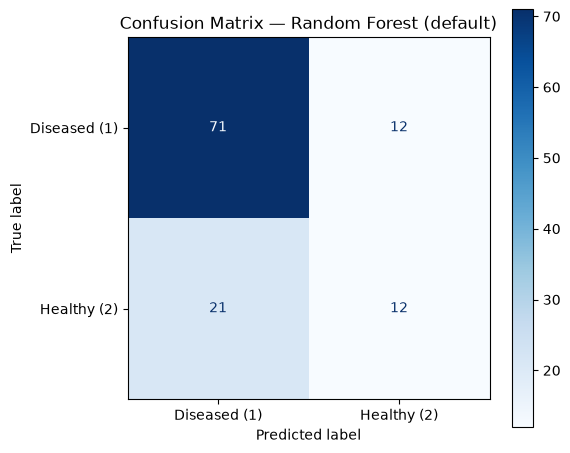

In [48]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Draw the confusion matrix for the best model (default Random Forest)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(
    rf, X_test, y_test,
    display_labels=['Diseased (1)', 'Healthy (2)'],
    cmap='Blues',
    ax=ax
)
plt.title('Confusion Matrix — Random Forest (default)')
plt.tight_layout()
plt.savefig('fig6_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

In [50]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Sex-stratified false-negative rate (FNR), averaged over repeated splits.
# FNR = of patients who ARE diseased (Class 1), the fraction predicted healthy (Class 2).
# Gender in df_clean: 0 = Female, 1 = Male.

X = df_clean.drop('Class', axis=1)
y = df_clean['Class']

def fnr(y_true, y_pred):
    diseased = (y_true == 1)
    if diseased.sum() == 0:
        return np.nan
    missed = ((y_true == 1) & (y_pred == 2)).sum()   # diseased but predicted healthy
    return missed / diseased.sum()

N_SPLITS = 100
store = {m: {'F': [], 'M': []} for m in ['LogReg', 'LogReg (balanced)', 'RF', 'RF (tuned)']}

for seed in range(N_SPLITS):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.2, random_state=seed, stratify=y)
    sc = StandardScaler()
    X_tr_s, X_te_s = sc.fit_transform(X_tr), sc.transform(X_te)

    g = X_te['Gender'].reset_index(drop=True)      # 0 = female, 1 = male
    yt = y_te.reset_index(drop=True)
    female, male = (g == 0), (g == 1)

    preds = {
        'LogReg':            LogisticRegression(max_iter=1000, random_state=42).fit(X_tr_s, y_tr).predict(X_te_s),
        'LogReg (balanced)': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced').fit(X_tr_s, y_tr).predict(X_te_s),
        'RF':                RandomForestClassifier(n_estimators=500, random_state=42).fit(X_tr, y_tr).predict(X_te),
        'RF (tuned)':        RandomForestClassifier(n_estimators=200, max_depth=None, min_samples_leaf=2, random_state=42).fit(X_tr, y_tr).predict(X_te),
    }
    for name, pred in preds.items():
        yp = pd.Series(pred).reset_index(drop=True)
        store[name]['F'].append(fnr(yt[female], yp[female]))
        store[name]['M'].append(fnr(yt[male],   yp[male]))

rows = []
for name, d in store.items():
    F, M = np.array(d['F']), np.array(d['M'])
    rows.append({
        'Model': name,
        'FNR Female': f"{np.nanmean(F):.3f} ± {np.nanstd(F):.3f}",
        'FNR Male':   f"{np.nanmean(M):.3f} ± {np.nanstd(M):.3f}",
        'Gap (F - M)': round(np.nanmean(F) - np.nanmean(M), 3),
    })

fnr_table = pd.DataFrame(rows).set_index('Model')
print(f"Sex-stratified FNR, averaged over {N_SPLITS} stratified splits:\n")
print(fnr_table.to_string())

Sex-stratified FNR, averaged over 100 stratified splits:

                      FNR Female       FNR Male  Gap (F - M)
Model                                                       
LogReg             0.165 ± 0.094  0.049 ± 0.038        0.116
LogReg (balanced)  0.606 ± 0.109  0.396 ± 0.060        0.210
RF                 0.231 ± 0.105  0.110 ± 0.041        0.120
RF (tuned)         0.229 ± 0.105  0.104 ± 0.043        0.125


In [53]:
summary_stats = df_clean.describe().round(2)
print(summary_stats)

          Age  Gender  Total_Bilirubin  Direct_Bilirubin  \
count  579.00  579.00           579.00            579.00   
mean    44.78    0.76             3.32              1.49   
std     16.22    0.43             6.23              2.82   
min      4.00    0.00             0.40              0.10   
25%     33.00    1.00             0.80              0.20   
50%     45.00    1.00             1.00              0.30   
75%     58.00    1.00             2.60              1.30   
max     90.00    1.00            75.00             19.70   

       Alkaline_Phosphotase  Alamine_Aminotransferase  \
count                579.00                    579.00   
mean                 291.37                     81.13   
std                  243.56                    183.18   
min                   63.00                     10.00   
25%                  175.50                     23.00   
50%                  208.00                     35.00   
75%                  298.00                     61.00   
max

In [54]:
# Feature selection: drop the redundant Direct_Bilirubin (r = 0.87 with Total_Bilirubin)
X_train_fs = X_train.drop('Direct_Bilirubin', axis=1)
X_test_fs  = X_test.drop('Direct_Bilirubin', axis=1)

rf_fs = RandomForestClassifier(n_estimators=500, random_state=42)
rf_fs.fit(X_train_fs, y_train)
y_pred_fs = rf_fs.predict(X_test_fs)

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
proba_fs = rf_fs.predict_proba(X_test_fs)[:, 0]
print("Accuracy:", round(accuracy_score(y_test, y_pred_fs), 3))
print("Macro-F1:", round(f1_score(y_test, y_pred_fs, average='macro'), 3))
print("ROC-AUC :", round(roc_auc_score((y_test == 1).astype(int), proba_fs), 3))
print(classification_report(y_test, y_pred_fs))

Accuracy: 0.716
Macro-F1: 0.597
ROC-AUC : 0.724
              precision    recall  f1-score   support

           1       0.76      0.88      0.82        83
           2       0.50      0.30      0.38        33

    accuracy                           0.72       116
   macro avg       0.63      0.59      0.60       116
weighted avg       0.69      0.72      0.69       116



In [55]:
# 5. Report the numbers
from sklearn.metrics import classification_report, f1_score, roc_auc_score

print(classification_report(y_test, y_pred_fs))
print("Macro-F1:", round(f1_score(y_test, y_pred_fs, average='macro'), 3))
print("ROC-AUC :", round(roc_auc_score(y_test, y_proba_fs), 3))

              precision    recall  f1-score   support

           1       0.76      0.88      0.82        83
           2       0.50      0.30      0.38        33

    accuracy                           0.72       116
   macro avg       0.63      0.59      0.60       116
weighted avg       0.69      0.72      0.69       116

Macro-F1: 0.597


NameError: name 'y_proba_fs' is not defined